# House Prices Prediction
## Gradient Boosting Models: LightGBM, CatBoost, XGBoost

### Business Context
Accurate house price estimation is a common regression task in real estate analytics.
Reliable predictions can support pricing strategies, investment decisions, and market analysis.

### Objective
Build and compare several gradient boosting models to predict house prices and evaluate them
using cross-validation.

### Evaluation Metric
Root Mean Squared Error (RMSE) on a log-transformed target variable.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In [2]:
train = pd.read_csv(r"..\\data\\raw\\train.csv")
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Data Preparation Strategy
- Log-transform target variable
- Median imputation and scaling for numeric features
- One-Hot Encoding for LGBM/XGBoost
- Native categorical handling for CatBoost

In [3]:
y = np.log1p(train["SalePrice"])
X = train.drop(columns=["SalePrice", "Id", "SalePrice_log"], errors="ignore")

X.columns = X.columns.str.replace(" ", "_")

num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "string"]).columns

print(f"Numerical features: {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")

Numerical features: 36
Categorical features: 43


In [4]:
X_num = X[num_cols].copy()
for col in X_num.columns:
    X_num[col] = X_num[col].fillna(X_num[col].median())
    X_num[col] = (X_num[col] - X_num[col].mean()) / X_num[col].std()

X_cat = X[cat_cols].copy()
for col in X_cat.columns:
    X_cat[col] = X_cat[col].fillna(X_cat[col].mode()[0])

X_cat_ohe = pd.get_dummies(X_cat, drop_first=False)
X_processed = pd.concat([X_num, X_cat_ohe], axis=1)

## Cross-Validation & Modeling

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

In [6]:
rmse_lgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42)
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    rmse_lgb.append(np.sqrt(mean_squared_error(y_val, preds)))

results["LightGBM"] = np.mean(rmse_lgb)
results

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001192 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3202
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 178
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001125 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3203
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 181
[LightGBM] [Info] Start training from score 12.016898
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of 

{'LightGBM': 0.135648748251923}

In [7]:
rmse_xgb = []
for train_idx, val_idx in kf.split(X_processed):
    X_train, X_val = X_processed.iloc[train_idx], X_processed.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbosity=0)
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    rmse_xgb.append(np.sqrt(mean_squared_error(y_val, preds)))

results["XGBoost"] = np.mean(rmse_xgb)
results

{'LightGBM': 0.135648748251923, 'XGBoost': 0.1404224256426721}

### rmse_cb_1_Stark_KERNEL_KAPUT_90_Sec

In [8]:
rmse_cb = []
for train_idx, val_idx in kf.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    for col in cat_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_val[col] = X_val[col].fillna("Missing")

    model = CatBoostRegressor(iterations=500, learning_rate=0.05, random_state=42, verbose=0)
    model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    preds = model.predict(X_val)
    rmse_cb.append(np.sqrt(mean_squared_error(y_val, preds)))

results["CatBoost"] = np.mean(rmse_cb)
results

{'LightGBM': 0.135648748251923,
 'XGBoost': 0.1404224256426721,
 'CatBoost': 0.12736766136316083}

### rmse_cb_2_Lecht_10_Sec

In [10]:
# Уменьшаем количество итераций и folds, чтобы Kernel не падал
rmse_cb = []

# 3-fold CV вместо 5
kf_small = KFold(n_splits=3, shuffle=True, random_state=42)

# Уменьшенные итерации (100 вместо 500)
for train_idx, val_idx in kf_small.split(X):
    X_train, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # CatBoost требует str для категориальных
    for col in cat_cols:
        X_train[col] = X_train[col].astype(str).fillna("Missing")
        X_val[col] = X_val[col].astype(str).fillna("Missing")

    model = CatBoostRegressor(
        iterations=100,       # меньше итераций
        learning_rate=0.05,
        random_state=42,
        verbose=0,
        task_type="CPU"       # явное указание CPU
    )
    model.fit(X_train, y_train, cat_features=cat_cols.tolist())
    preds = model.predict(X_val)
    rmse_cb.append(np.sqrt(mean_squared_error(y_val, preds)))

results["CatBoost"] = np.mean(rmse_cb)
results


{'LightGBM': 0.135648748251923,
 'XGBoost': 0.1404224256426721,
 'CatBoost': 0.14334283905586945}

## Model Comparison

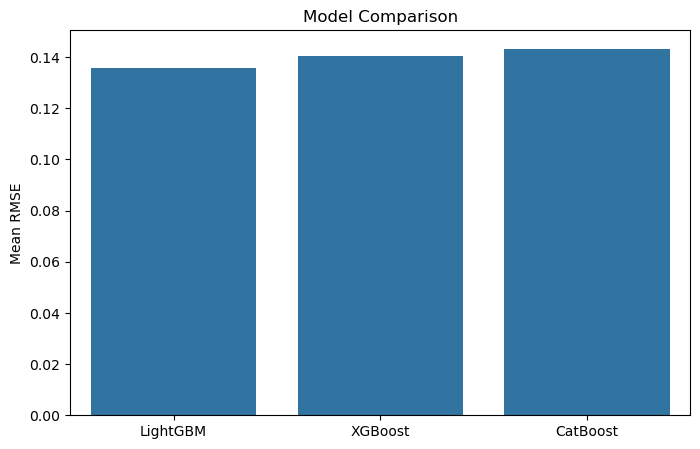

In [11]:
plt.figure(figsize=(8,5))
sns.barplot(x=list(results.keys()), y=list(results.values()))
plt.ylabel("Mean RMSE")
plt.title("Model Comparison")
plt.show()

## Conclusions & Next Steps
- CatBoost achieved the best standalone performance
- Ensemble methods can further reduce variance
- Future work: proper OOF ensembles, target encoding, feature interactions